In [1]:
# 12. Write a ML code for customer segmentation (dataset attached) using K-Means cluster algorithm,
#  considering Annual Income (k$)' and Spending Score (1-100) and also plot the cluster segmentation plot 
# (scatter plot of cluster result).

# Use sklearn
# Number of cluster =5.

# Note: You dont need to download the dataset from Kaggle. The dataset is already attached here.
# Just for your kind information it is take from Kaggle
# https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

In [3]:
import pandas as pd

# load dataset
data = pd.read_csv('Mall_Customers.csv')

display(data.info())

# since no null value contain do no processing needed for null value. Now we will select the required columns for clustering.

# data selection for clustering
X = data[['Annual Income (k$)', 'Spending Score (1-100)']]




<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


None

In [18]:
# apply k-means cluster with 5 clusters
from sklearn.cluster import KMeans

n = 5 # taking n clusters 
kmeans = KMeans(n_clusters=n, random_state=0)

# display the cluster centers
data['Cluster'] = kmeans.fit_predict(X)



In [23]:
print(data.shape)
print(X.head())
print(data['Cluster'].value_counts())

(200, 6)
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40
Cluster
0    81
1    39
2    35
3    23
4    22
Name: count, dtype: int64


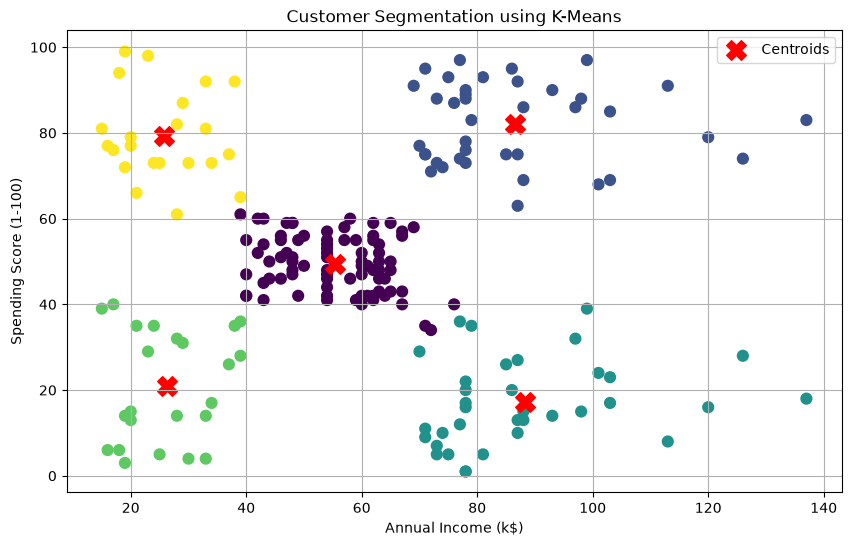

In [ ]:
import matplotlib.pyplot as plt
#plot the cluster segmentation plot (scatter plot of cluster result)
plt.figure(figsize=(10, 6))

plt.scatter(
    data['Annual Income (k$)'],
    data['Spending Score (1-100)'],
    c=data['Cluster'],
    cmap='viridis',
    s=60
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Centroids'
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True)
plt.show()